# Logistic Regression dự đoán rủi ro tài chính

Bản này giữ nguyên cấu trúc code cũ và bổ sung phần **18.3 Phân tích dữ liệu/đặc trưng ảnh hưởng đến kết quả phân nhãn**.

In [ ]:
# ============================================================
# 1. KHAI BÁO THƯ VIỆN
# ============================================================

import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve
)


In [ ]:
# ============================================================
# 2. ĐỌC DỮ LIỆU TỪ FILE CSV CÓ SẴN
# ============================================================

# Nếu file german_credit_data.csv nằm cùng thư mục với file .py
LOCAL_CSV = "german_credit_data (1).csv"

# Nếu file nằm ở thư mục khác thì thay bằng đường dẫn đầy đủ, ví dụ:
# LOCAL_CSV = r"D:\Dataset\german_credit_data.csv"

def load_dataset():
    """Đọc dữ liệu German Credit Risk từ file CSV."""

    if not os.path.exists(LOCAL_CSV):
        raise FileNotFoundError(
            f"Không tìm thấy file '{LOCAL_CSV}'. "
            "Hãy kiểm tra lại đường dẫn hoặc đặt file cùng thư mục với chương trình."
        )

    print("Đang đọc dữ liệu từ:", LOCAL_CSV)

    df = pd.read_csv(LOCAL_CSV)

    print("Đọc dữ liệu thành công!")
    print("Kích thước dữ liệu:", df.shape)

    return df


# Đọc dữ liệu
df = load_dataset()


Đang đọc dữ liệu từ: german_credit_data (1).csv
Đọc dữ liệu thành công!
Kích thước dữ liệu: (1000, 11)


In [ ]:
# ============================================================
# 3. KHÁM PHÁ DỮ LIỆU BAN ĐẦU
# ============================================================

print("\n===== 5 DÒNG DỮ LIỆU ĐẦU TIÊN =====")
print(df.head())

print("\n===== KÍCH THƯỚC DỮ LIỆU =====")
print(df.shape)

print("\n===== THÔNG TIN DỮ LIỆU =====")
print(df.info())

print("\n===== THỐNG KÊ MÔ TẢ =====")
print(df.describe(include="all"))



===== 5 DÒNG DỮ LIỆU ĐẦU TIÊN =====
   Unnamed: 0  Age     Sex  Job Housing Saving accounts Checking account  \
0           0   67    male    2     own             NaN           little   
1           1   22  female    2     own          little         moderate   
2           2   49    male    1     own          little              NaN   
3           3   45    male    2    free          little           little   
4           4   53    male    2    free          little           little   

   Credit amount  Duration              Purpose  Risk  
0           1169         6             radio/TV  good  
1           5951        48             radio/TV   bad  
2           2096        12            education  good  
3           7882        42  furniture/equipment  good  
4           4870        24                  car   bad  

===== KÍCH THƯỚC DỮ LIỆU =====
(1000, 11)

===== THÔNG TIN DỮ LIỆU =====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 

In [ ]:
# ============================================================
# 4. LÀM SẠCH DỮ LIỆU
# ============================================================

# Chuẩn hóa tên cột: bỏ khoảng trắng thừa
# Ví dụ: "Credit amount" vẫn giữ nguyên, chỉ bỏ khoảng trắng đầu/cuối.
df.columns = df.columns.str.strip()

# Xóa cột chỉ số nếu có, thường là "Unnamed: 0" trong file Kaggle
for col in df.columns:
    if col.lower().startswith("unnamed"):
        df = df.drop(columns=[col])

print("\n===== DANH SÁCH CỘT SAU KHI LÀM SẠCH TÊN CỘT =====")
print(df.columns.tolist())

# Kiểm tra dữ liệu thiếu
print("\n===== SỐ GIÁ TRỊ THIẾU Ở MỖI CỘT =====")
print(df.isnull().sum())

# Xóa dòng trùng lặp nếu có
before_rows = df.shape[0]
df = df.drop_duplicates()
after_rows = df.shape[0]
print(f"\nĐã xóa {before_rows - after_rows} dòng trùng lặp.")



===== DANH SÁCH CỘT SAU KHI LÀM SẠCH TÊN CỘT =====
['Age', 'Sex', 'Job', 'Housing', 'Saving accounts', 'Checking account', 'Credit amount', 'Duration', 'Purpose', 'Risk']

===== SỐ GIÁ TRỊ THIẾU Ở MỖI CỘT =====
Age                   0
Sex                   0
Job                   0
Housing               0
Saving accounts     183
Checking account    394
Credit amount         0
Duration              0
Purpose               0
Risk                  0
dtype: int64

Đã xóa 0 dòng trùng lặp.


In [ ]:
# ============================================================
# 5. XÁC ĐỊNH NHÃN DỰ ĐOÁN
# ============================================================
# Trong German Credit Risk, cột Risk thường có giá trị:
#   good = khách hàng rủi ro thấp
#   bad  = khách hàng rủi ro cao
#
# Ta quy đổi:
#   good -> 0
#   bad  -> 1
#
# Khi đánh giá, lớp 1 là lớp quan trọng vì đây là nhóm rủi ro cao.

TARGET_COL = "Risk"

if TARGET_COL not in df.columns:
    raise ValueError("Không tìm thấy cột Risk trong dữ liệu. Hãy kiểm tra lại file CSV.")

print("\n===== GIÁ TRỊ CỦA CỘT RISK TRƯỚC KHI MÃ HÓA =====")
print(df[TARGET_COL].value_counts(dropna=False))

# Quy đổi nhãn sang 0/1
risk_map = {
    "good": 0,
    "bad": 1,
    "Good": 0,
    "Bad": 1,
    1: 0,   # phòng trường hợp dữ liệu dùng 1 là good
    2: 1    # phòng trường hợp dữ liệu dùng 2 là bad
}

y = df[TARGET_COL].map(risk_map)

# Nếu map bị lỗi, thử xử lý dạng chuỗi tổng quát
if y.isnull().any():
    y = df[TARGET_COL].astype(str).str.lower().map({"good": 0, "bad": 1})

if y.isnull().any():
    raise ValueError("Không mã hóa được cột Risk. Hãy kiểm tra các giá trị nhãn trong cột này.")

y = y.astype(int).values

# X là toàn bộ thuộc tính đầu vào, bỏ cột nhãn Risk
X_raw = df.drop(columns=[TARGET_COL])

print("\n===== PHÂN BỐ NHÃN SAU KHI MÃ HÓA =====")
print(pd.Series(y).value_counts().rename(index={0: "Rủi ro thấp/good", 1: "Rủi ro cao/bad"}))



===== GIÁ TRỊ CỦA CỘT RISK TRƯỚC KHI MÃ HÓA =====
Risk
good    700
bad     300
Name: count, dtype: int64

===== PHÂN BỐ NHÃN SAU KHI MÃ HÓA =====
Rủi ro thấp/good    700
Rủi ro cao/bad      300
Name: count, dtype: int64


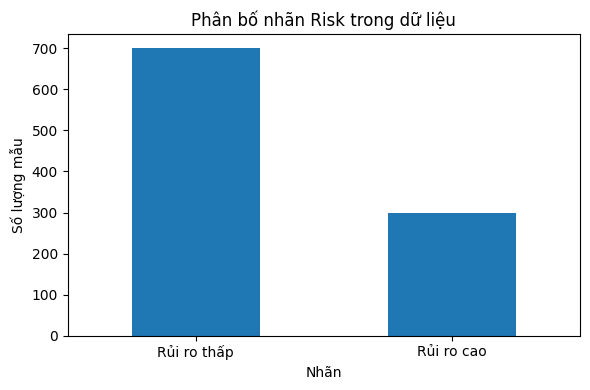

In [ ]:
# ============================================================
# 6. VẼ PHÂN BỐ NHÃN
# ============================================================

OUTPUT_DIR = "outputs_kaggle_credit_risk"
os.makedirs(OUTPUT_DIR, exist_ok=True)

plt.figure(figsize=(6, 4))
pd.Series(y).value_counts().sort_index().plot(kind="bar")
plt.xticks([0, 1], ["Rủi ro thấp", "Rủi ro cao"], rotation=0)
plt.xlabel("Nhãn")
plt.ylabel("Số lượng mẫu")
plt.title("Phân bố nhãn Risk trong dữ liệu")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "fig_label_distribution.png"), dpi=300)
plt.show()


In [ ]:
# ============================================================
# 7. CHIA DỮ LIỆU TRAIN / TEST
# ============================================================
# stratify=y giúp tỉ lệ lớp good/bad ở train và test tương đối giống nhau.

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nSố mẫu train:", X_train_raw.shape[0])
print("Số mẫu test :", X_test_raw.shape[0])



Số mẫu train: 800
Số mẫu test : 200


In [ ]:
# ============================================================
# 8. TIỀN XỬ LÝ DỮ LIỆU (ĐÃ TỐI ƯU + SMOTE)
# ============================================================

# Cài thư viện SMOTE
!pip install imbalanced-learn -q

from imblearn.over_sampling import SMOTE

class StandardScalerManual:
    """
    Tự xây dựng kỹ thuật chuẩn hóa dữ liệu theo công thức Z-score.
    Z-score: x' = (x - mean) / std
    """

    def __init__(self):
        self.mean_ = None
        self.std_ = None
        self.is_fitted = False

    def fit(self, X):
        self.mean_ = np.mean(X, axis=0)
        self.std_  = np.std(X, axis=0)
        self.std_[self.std_ == 0] = 1
        self.is_fitted = True
        return self

    def transform(self, X):
        if not self.is_fitted:
            raise RuntimeError("StandardScalerManual chưa được fit. Hãy gọi fit() trước.")
        return (X - self.mean_) / self.std_

    def fit_transform(self, X):
        return self.fit(X).transform(X)

    def inverse_transform(self, X):
        if not self.is_fitted:
            raise RuntimeError("StandardScalerManual chưa được fit.")
        return X * self.std_ + self.mean_

    def get_params(self):
        if not self.is_fitted:
            return {}
        return {"mean": self.mean_, "std": self.std_}


def create_onehot_encoder():
    """Tạo OneHotEncoder tương thích nhiều phiên bản scikit-learn."""
    try:
        return OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:
        return OneHotEncoder(handle_unknown="ignore", sparse=False)


def fit_preprocessor(X_train, use_scaler=False):
    """Fit các bước tiền xử lý trên tập train."""

    numeric_cols     = X_train.select_dtypes(include=[np.number]).columns.tolist()
    categorical_cols = X_train.select_dtypes(exclude=[np.number]).columns.tolist()

    print("\n===== BÁO CÁO GIÁ TRỊ THIẾU =====")
    missing = X_train.isnull().sum()
    missing = missing[missing > 0]
    if len(missing) == 0:
        print("Không có giá trị thiếu.")
    else:
        for col, count in missing.items():
            pct = count / len(X_train) * 100
            print(f"  {col}: {count} giá trị thiếu ({pct:.1f}%)")

    numeric_medians = X_train[numeric_cols].median() if numeric_cols else pd.Series(dtype=float)

    # NA trong Saving/Checking account = không có tài khoản, điền "none"
    NA_AS_NONE_COLS = {"Saving accounts", "Checking account"}

    categorical_modes = {}
    for col in categorical_cols:
        if col in NA_AS_NONE_COLS:
            categorical_modes[col] = "none"
        else:
            mode_value = X_train[col].mode(dropna=True)
            categorical_modes[col] = mode_value.iloc[0] if len(mode_value) > 0 else "unknown"

    encoder = create_onehot_encoder()
    if categorical_cols:
        X_cat = X_train[categorical_cols].copy()
        for col in categorical_cols:
            X_cat[col] = X_cat[col].fillna(categorical_modes[col]).astype(str)
        encoder.fit(X_cat)
    else:
        encoder = None

    info = {
        "numeric_cols":      numeric_cols,
        "categorical_cols":  categorical_cols,
        "numeric_medians":   numeric_medians,
        "categorical_modes": categorical_modes,
        "encoder":           encoder,
        "use_scaler":        use_scaler,
        "scaler":            None,
        "feature_names":     None
    }

    X_train_processed = transform_preprocessor(X_train, info, fit_stage=True)

    if use_scaler:
        scaler = StandardScalerManual()
        X_train_processed = scaler.fit_transform(X_train_processed)
        info["scaler"] = scaler

        params = scaler.get_params()
        print("\n===== THỐNG KÊ SAU KHI CHUẨN HÓA Z-SCORE =====")
        for i, name in enumerate(info["feature_names"]):
            print(f"  {name:35s} | mean={params['mean'][i]:10.4f} | std={params['std'][i]:10.4f}")

    return info


def transform_preprocessor(X, info, fit_stage=False):
    """Biến đổi dữ liệu theo bộ tiền xử lý đã fit."""

    numeric_cols      = info["numeric_cols"]
    categorical_cols  = info["categorical_cols"]
    numeric_medians   = info["numeric_medians"]
    categorical_modes = info["categorical_modes"]
    encoder           = info["encoder"]

    required_cols = set(numeric_cols + categorical_cols)
    missing_cols  = required_cols - set(X.columns)
    if missing_cols:
        raise ValueError(
            f"Dữ liệu đầu vào thiếu các cột: {missing_cols}\n"
            f"Các cột hiện có: {list(X.columns)}"
        )

    parts         = []
    feature_names = []

    if numeric_cols:
        X_num = X[numeric_cols].copy()
        X_num = X_num.fillna(numeric_medians)
        parts.append(X_num.values.astype(float))
        feature_names.extend(numeric_cols)

    if categorical_cols:
        X_cat = X[categorical_cols].copy()
        for col in categorical_cols:
            X_cat[col] = X_cat[col].fillna(categorical_modes[col]).astype(str)

        X_cat_encoded = encoder.transform(X_cat)
        parts.append(X_cat_encoded.astype(float))

        try:
            cat_feature_names = encoder.get_feature_names_out(categorical_cols).tolist()
        except Exception:
            cat_feature_names = []
            for col, cats in zip(categorical_cols, encoder.categories_):
                cat_feature_names.extend([f"{col}_{cat}" for cat in cats])

        feature_names.extend(cat_feature_names)

    X_processed = np.hstack(parts)

    if fit_stage:
        info["feature_names"] = feature_names
        print("\n===== TÓM TẮT ĐẶC TRƯNG SAU MÃ HÓA =====")
        print(f"  Số đặc trưng số (numeric)        : {len(numeric_cols)}")
        print(f"  Số đặc trưng chữ (categorical)   : {len(categorical_cols)}")
        print(f"  Số đặc trưng sau One-Hot Encoding : {len(cat_feature_names) if categorical_cols else 0}")
        print(f"  Tổng số đặc trưng đầu vào mô hình: {X_processed.shape[1]}")

    if info["use_scaler"] and info["scaler"] is not None:
        X_processed = info["scaler"].transform(X_processed)

    return X_processed


In [ ]:
# ============================================================
# CHẠY TIỀN XỬ LÝ
# ============================================================

# Bộ dữ liệu 1: Trước khi dùng kỹ thuật chuẩn hóa
print("\n" + "="*60)
print("BỘ DỮ LIỆU 1: TRƯỚC KHI DÙNG KỸ THUẬT CHUẨN HÓA")
print("="*60)
prep_no_scaler    = fit_preprocessor(X_train_raw, use_scaler=False)
X_train_no_scaler = transform_preprocessor(X_train_raw, prep_no_scaler)
X_test_no_scaler  = transform_preprocessor(X_test_raw,  prep_no_scaler)

# Bộ dữ liệu 2: Sau khi dùng kỹ thuật chuẩn hóa
print("\n" + "="*60)
print("BỘ DỮ LIỆU 2: SAU KHI DÙNG KỸ THUẬT CHUẨN HÓA (Z-SCORE)")
print("="*60)
prep_scaler    = fit_preprocessor(X_train_raw, use_scaler=True)
X_train_scaler = transform_preprocessor(X_train_raw, prep_scaler)
X_test_scaler  = transform_preprocessor(X_test_raw,  prep_scaler)

# Bộ dữ liệu 3: Sau chuẩn hóa + SMOTE cân bằng lớp
print("\n" + "="*60)
print("BỘ DỮ LIỆU 3: SAU CHUẨN HÓA + SMOTE CÂN BẰNG LỚP")
print("="*60)

smote = SMOTE(random_state=42)
X_train_balanced, y_train_balanced = smote.fit_resample(X_train_scaler, y_train)

print("\n===== SMOTE CÂN BẰNG LỚP =====")
print(f"  Trước: Rủi ro thấp={np.sum(y_train==0)}, Rủi ro cao={np.sum(y_train==1)} "
      f"(tỷ lệ {np.sum(y_train==1)/len(y_train)*100:.1f}%)")
print(f"  Sau  : Rủi ro thấp={np.sum(y_train_balanced==0)}, Rủi ro cao={np.sum(y_train_balanced==1)} "
      f"(tỷ lệ 50.0%)")
print(f"  Tổng mẫu train sau SMOTE: {len(y_train_balanced)}")

print("\nKích thước dữ liệu sau mã hóa     :", X_train_scaler.shape)
print("Kích thước dữ liệu sau SMOTE      :", X_train_balanced.shape)
print("Số lượng đặc trưng sau One-Hot    :", len(prep_scaler["feature_names"]))



BỘ DỮ LIỆU 1: TRƯỚC KHI DÙNG KỸ THUẬT CHUẨN HÓA

===== BÁO CÁO GIÁ TRỊ THIẾU =====
  Saving accounts: 144 giá trị thiếu (18.0%)
  Checking account: 316 giá trị thiếu (39.5%)

===== TÓM TẮT ĐẶC TRƯNG SAU MÃ HÓA =====
  Số đặc trưng số (numeric)        : 4
  Số đặc trưng chữ (categorical)   : 5
  Số đặc trưng sau One-Hot Encoding : 22
  Tổng số đặc trưng đầu vào mô hình: 26

BỘ DỮ LIỆU 2: SAU KHI DÙNG KỸ THUẬT CHUẨN HÓA (Z-SCORE)

===== BÁO CÁO GIÁ TRỊ THIẾU =====
  Saving accounts: 144 giá trị thiếu (18.0%)
  Checking account: 316 giá trị thiếu (39.5%)

===== TÓM TẮT ĐẶC TRƯNG SAU MÃ HÓA =====
  Số đặc trưng số (numeric)        : 4
  Số đặc trưng chữ (categorical)   : 5
  Số đặc trưng sau One-Hot Encoding : 22
  Tổng số đặc trưng đầu vào mô hình: 26

===== THỐNG KÊ SAU KHI CHUẨN HÓA Z-SCORE =====
  Age                                 | mean=   35.3237 | std=   11.0384
  Job                                 | mean=    1.9062 | std=    0.6422
  Credit amount                       | mean= 

In [ ]:
# ============================================================
# 9. XÂY DỰNG LOGISTIC REGRESSION TỪ ĐẦU
# ============================================================

class LogisticRegressionScratch:
    """Mô hình hồi quy Logistic tự xây dựng bằng NumPy."""

    def __init__(self, learning_rate=0.01, n_iterations=1000, lambda_reg=0.0, verbose=False):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.lambda_reg = lambda_reg
        self.verbose = verbose
        self.weights = None
        self.bias = None
        self.loss_history = []

    def sigmoid(self, z):
        z = np.clip(z, -500, 500)
        return 1 / (1 + np.exp(-z))

    def compute_loss(self, y_true, y_prob):
        m = y_true.shape[0]
        eps = 1e-9
        y_true = y_true.reshape(-1, 1)

        bce = -np.mean(
            y_true * np.log(y_prob + eps)
            + (1 - y_true) * np.log(1 - y_prob + eps)
        )

        l2 = (self.lambda_reg / (2 * m)) * np.sum(self.weights ** 2)
        return bce + l2

    def fit(self, X, y):
        m, n_features = X.shape
        y = y.reshape(-1, 1)

        self.weights = np.zeros((n_features, 1))
        self.bias = 0.0
        self.loss_history = []

        for i in range(self.n_iterations):
            z = np.dot(X, self.weights) + self.bias
            y_prob = self.sigmoid(z)

            loss = self.compute_loss(y, y_prob)
            self.loss_history.append(loss)

            dw = (1 / m) * np.dot(X.T, (y_prob - y))
            db = (1 / m) * np.sum(y_prob - y)

            # L2 regularization, không phạt bias
            dw += (self.lambda_reg / m) * self.weights

            self.weights -= self.learning_rate * dw
            self.bias -= self.learning_rate * db

            if self.verbose and (i + 1) % 200 == 0:
                print(f"Vòng lặp {i + 1}/{self.n_iterations}, Loss = {loss:.6f}")

        return self

    def predict_proba(self, X):
        z = np.dot(X, self.weights) + self.bias
        return self.sigmoid(z).ravel()

    def predict(self, X, threshold=0.5):
        prob = self.predict_proba(X)
        return (prob >= threshold).astype(int)


In [ ]:
# ============================================================
# 10. HÀM ĐÁNH GIÁ MÔ HÌNH
# ============================================================

def evaluate_model(name, y_true, y_pred, y_prob=None):
    """Tính Accuracy, Precision, Recall, F1-score, ROC-AUC."""

    result = {
        "Mo_hinh": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1_score": f1_score(y_true, y_pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_true, y_prob) if y_prob is not None else np.nan
    }

    print("\n=====", name, "=====")
    print("Accuracy :", round(result["Accuracy"], 4))
    print("Precision:", round(result["Precision"], 4))
    print("Recall   :", round(result["Recall"], 4))
    print("F1-score :", round(result["F1_score"], 4))
    if y_prob is not None:
        print("ROC-AUC  :", round(result["ROC_AUC"], 4))
    print("\nMa trận nhầm lẫn:")
    print(confusion_matrix(y_true, y_pred))
    print("\nClassification report:")
    print(classification_report(y_true, y_pred, target_names=["Rủi ro thấp", "Rủi ro cao"], zero_division=0))

    return result


In [ ]:
# ============================================================
# 11. THÍ NGHIỆM 1: TRƯỚC KHI DÙNG KỸ THUẬT CHUẨN HÓA
# ============================================================
# Vì dữ liệu chưa chuẩn hóa có thang đo rất khác nhau, learning_rate phải nhỏ.
# Kết quả này dùng làm mốc so sánh "trước khi dùng kỹ thuật".

model_before = LogisticRegressionScratch(
    learning_rate=0.000001,
    n_iterations=3000,
    lambda_reg=0.0,
    verbose=False
)

model_before.fit(X_train_no_scaler, y_train)
y_prob_before = model_before.predict_proba(X_test_no_scaler)
y_pred_before = model_before.predict(X_test_no_scaler, threshold=0.5)

result_before = evaluate_model(
    "Logistic tự xây dựng - Trước chuẩn hóa",
    y_test,
    y_pred_before,
    y_prob_before
)



===== Logistic tự xây dựng - Trước chuẩn hóa =====
Accuracy : 0.7
Precision: 0.5
Recall   : 0.1167
F1-score : 0.1892
ROC-AUC  : 0.6804

Ma trận nhầm lẫn:
[[133   7]
 [ 53   7]]

Classification report:
              precision    recall  f1-score   support

 Rủi ro thấp       0.72      0.95      0.82       140
  Rủi ro cao       0.50      0.12      0.19        60

    accuracy                           0.70       200
   macro avg       0.61      0.53      0.50       200
weighted avg       0.65      0.70      0.63       200




===== Logistic tự xây dựng - Sau chuẩn hóa StandardScaler =====
Accuracy : 0.72
Precision: 0.5263
Recall   : 0.6667
F1-score : 0.5882
ROC-AUC  : 0.7564

Ma trận nhầm lẫn:
[[104  36]
 [ 20  40]]

Classification report:
              precision    recall  f1-score   support

 Rủi ro thấp       0.84      0.74      0.79       140
  Rủi ro cao       0.53      0.67      0.59        60

    accuracy                           0.72       200
   macro avg       0.68      0.70      0.69       200
weighted avg       0.74      0.72      0.73       200



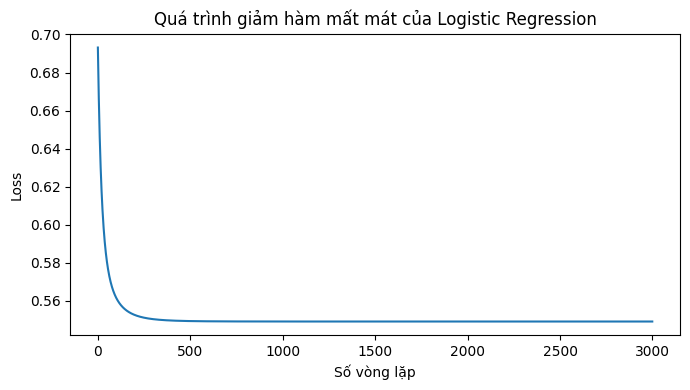

In [ ]:
# ============================================================
# 12. THÍ NGHIỆM 2: SAU KHI DÙNG KỸ THUẬT CHUẨN HÓA
# ============================================================
# Sau khi chuẩn hóa, mô hình học ổn định hơn và có thể dùng learning_rate lớn hơn.

model_after = LogisticRegressionScratch(
    learning_rate=0.05,
    n_iterations=3000,
    lambda_reg=0.0,
    verbose=False
)

model_after.fit(X_train_balanced, y_train_balanced)
y_prob_after = model_after.predict_proba(X_test_scaler)
y_pred_after = model_after.predict(X_test_scaler, threshold=0.5)

result_after = evaluate_model(
    "Logistic tự xây dựng - Sau chuẩn hóa StandardScaler",
    y_test,
    y_pred_after,
    y_prob_after
)


# Vẽ biểu đồ loss sau chuẩn hóa
plt.figure(figsize=(7, 4))
plt.plot(model_after.loss_history)
plt.xlabel("Số vòng lặp")
plt.ylabel("Loss")
plt.title("Quá trình giảm hàm mất mát của Logistic Regression")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "fig_loss_logistic.png"), dpi=300)
plt.show()


In [ ]:
# ============================================================
# 13. THÍ NGHIỆM 3: ĐIỀU CHỈNH THAM SỐ LOGISTIC REGRESSION
# ============================================================
# Điều chỉnh:
#   - learning_rate
#   - lambda_reg: hệ số L2 regularization
#   - threshold: ngưỡng phân loại
#
# Trong bài toán rủi ro tài chính, Recall của lớp rủi ro cao rất quan trọng
# vì bỏ sót khách hàng rủi ro cao có thể gây thiệt hại.

param_grid = [
    {"learning_rate": 0.05, "lambda_reg": 0.01,  "threshold": 0.3},
    {"learning_rate": 0.05, "lambda_reg": 0.01,  "threshold": 0.4},
    {"learning_rate": 0.05, "lambda_reg": 0.01, "threshold": 0.5},
    {"learning_rate": 0.01, "lambda_reg": 0.00,  "threshold": 0.3},
    {"learning_rate": 0.01, "lambda_reg": 0.01, "threshold": 0.4},
    {"learning_rate": 0.05, "lambda_reg": 0.02, "threshold": 0.3},
]

experiment_results = []
best_model = None
best_score = -1
best_setting = None

for i, params in enumerate(param_grid, start=1):
    print("\n====================================")
    print("THÍ NGHIỆM", i, params)
    print("====================================")

    model = LogisticRegressionScratch(
        learning_rate=params["learning_rate"],
        n_iterations=3000,
        lambda_reg=params["lambda_reg"],
        verbose=False
    )

    model.fit(X_train_balanced, y_train_balanced)
    y_prob = model.predict_proba(X_test_scaler)
    y_pred = (y_prob >= params["threshold"]).astype(int)

    result = evaluate_model(
        f"TN{i} - LR={params['learning_rate']}, L2={params['lambda_reg']}, threshold={params['threshold']}",
        y_test,
        y_pred,
        y_prob
    )

    result.update(params)
    experiment_results.append(result)

    # Chọn theo F1-score. Có thể đổi sang Recall nếu nhóm muốn ưu tiên bắt rủi ro cao.
    if result["F1_score"] > best_score:
        best_score = result["F1_score"]
        best_model = model
        best_setting = params

experiment_df = pd.DataFrame(experiment_results)
experiment_df.to_csv(os.path.join(OUTPUT_DIR, "bang_khao_nghiem_logistic.csv"), index=False)

print("\n===== BẢNG KẾT QUẢ KHẢO NGHIỆM LOGISTIC =====")
print(experiment_df[["Mo_hinh", "learning_rate", "lambda_reg", "threshold", "Accuracy", "Precision", "Recall", "F1_score", "ROC_AUC"]])

print("\n===== THAM SỐ TỐT NHẤT =====")
print(best_setting)



THÍ NGHIỆM 1 {'learning_rate': 0.05, 'lambda_reg': 0.01, 'threshold': 0.3}

===== TN1 - LR=0.05, L2=0.01, threshold=0.3 =====
Accuracy : 0.565
Precision: 0.3969
Recall   : 0.8667
F1-score : 0.5445
ROC-AUC  : 0.7564

Ma trận nhầm lẫn:
[[61 79]
 [ 8 52]]

Classification report:
              precision    recall  f1-score   support

 Rủi ro thấp       0.88      0.44      0.58       140
  Rủi ro cao       0.40      0.87      0.54        60

    accuracy                           0.56       200
   macro avg       0.64      0.65      0.56       200
weighted avg       0.74      0.56      0.57       200


THÍ NGHIỆM 2 {'learning_rate': 0.05, 'lambda_reg': 0.01, 'threshold': 0.4}

===== TN2 - LR=0.05, L2=0.01, threshold=0.4 =====
Accuracy : 0.665
Precision: 0.466
Recall   : 0.8
F1-score : 0.589
ROC-AUC  : 0.7564

Ma trận nhầm lẫn:
[[85 55]
 [12 48]]

Classification report:
              precision    recall  f1-score   support

 Rủi ro thấp       0.88      0.61      0.72       140
  Rủi ro cao 

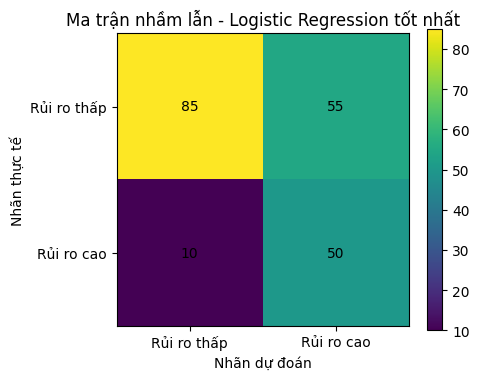

In [ ]:
# ============================================================
# 14. VẼ MA TRẬN NHẦM LẪN CỦA MÔ HÌNH TỐT NHẤT
# ============================================================

best_prob = best_model.predict_proba(X_test_scaler)
best_pred = (best_prob >= best_setting["threshold"]).astype(int)

cm = confusion_matrix(y_test, best_pred)
plt.figure(figsize=(5, 4))
plt.imshow(cm)
plt.title("Ma trận nhầm lẫn - Logistic Regression tốt nhất")
plt.xlabel("Nhãn dự đoán")
plt.ylabel("Nhãn thực tế")
plt.xticks([0, 1], ["Rủi ro thấp", "Rủi ro cao"])
plt.yticks([0, 1], ["Rủi ro thấp", "Rủi ro cao"])

for row in range(2):
    for col in range(2):
        plt.text(col, row, cm[row, col], ha="center", va="center")

plt.colorbar()
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "fig_confusion_matrix.png"), dpi=300)
plt.show()



===== SO SÁNH TRƯỚC VÀ SAU KHI DÙNG KỸ THUẬT CHUẨN HÓA =====
                                             Mo_hinh  Accuracy  Precision  \
0             Logistic tự xây dựng - Trước chuẩn hóa      0.70   0.500000   
1  Logistic tự xây dựng - Sau chuẩn hóa StandardS...      0.72   0.526316   

     Recall  F1_score   ROC_AUC  
0  0.116667  0.189189  0.680357  
1  0.666667  0.588235  0.756429  


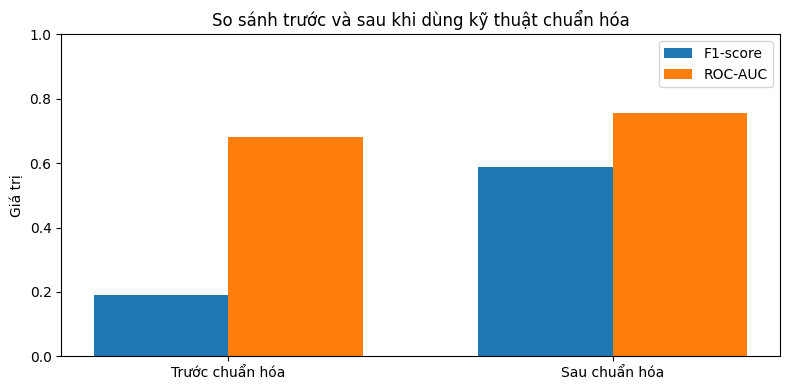

In [ ]:
# ============================================================
# 15. SO SÁNH TRƯỚC VÀ SAU KHI DÙNG KỸ THUẬT
# ============================================================

before_after_df = pd.DataFrame([result_before, result_after])
before_after_df.to_csv(os.path.join(OUTPUT_DIR, "bang_so_sanh_truoc_sau_chuan_hoa.csv"), index=False)

print("\n===== SO SÁNH TRƯỚC VÀ SAU KHI DÙNG KỸ THUẬT CHUẨN HÓA =====")
print(before_after_df[["Mo_hinh", "Accuracy", "Precision", "Recall", "F1_score", "ROC_AUC"]])

plt.figure(figsize=(8, 4))
labels = ["Trước chuẩn hóa", "Sau chuẩn hóa"]
f1_values = before_after_df["F1_score"].values
auc_values = before_after_df["ROC_AUC"].values

x = np.arange(len(labels))
width = 0.35
plt.bar(x - width/2, f1_values, width, label="F1-score")
plt.bar(x + width/2, auc_values, width, label="ROC-AUC")
plt.xticks(x, labels)
plt.ylim(0, 1)
plt.ylabel("Giá trị")
plt.title("So sánh trước và sau khi dùng kỹ thuật chuẩn hóa")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "fig_before_after_scaling.png"), dpi=300)
plt.show()


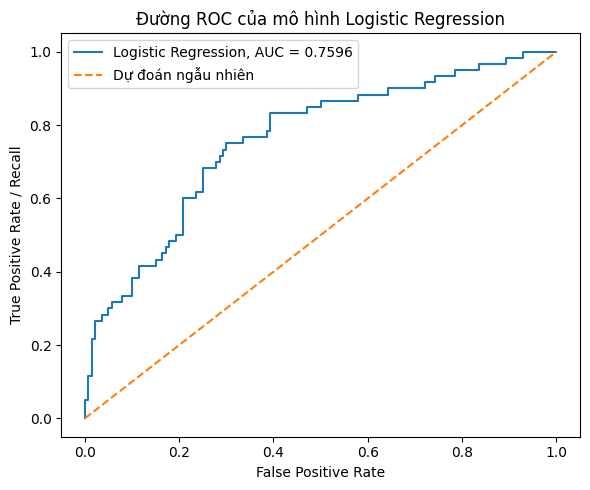

In [ ]:
# ============================================================
# 16. VẼ ĐƯỜNG ROC CHO MÔ HÌNH LOGISTIC TỐT NHẤT
# ============================================================

fpr, tpr, thresholds = roc_curve(y_test, best_prob)
best_auc = roc_auc_score(y_test, best_prob)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"Logistic Regression, AUC = {best_auc:.4f}")
plt.plot([0, 1], [0, 1], linestyle="--", label="Dự đoán ngẫu nhiên")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate / Recall")
plt.title("Đường ROC của mô hình Logistic Regression")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "fig_roc_logistic.png"), dpi=300)
plt.show()



===== Decision Tree mở rộng =====
Accuracy : 0.68
Precision: 0.4722
Recall   : 0.5667
F1-score : 0.5152
ROC-AUC  : 0.7093

Ma trận nhầm lẫn:
[[102  38]
 [ 26  34]]

Classification report:
              precision    recall  f1-score   support

 Rủi ro thấp       0.80      0.73      0.76       140
  Rủi ro cao       0.47      0.57      0.52        60

    accuracy                           0.68       200
   macro avg       0.63      0.65      0.64       200
weighted avg       0.70      0.68      0.69       200


Tham số tốt nhất của Decision Tree:
{'criterion': 'entropy', 'max_depth': 3, 'min_samples_leaf': 1}


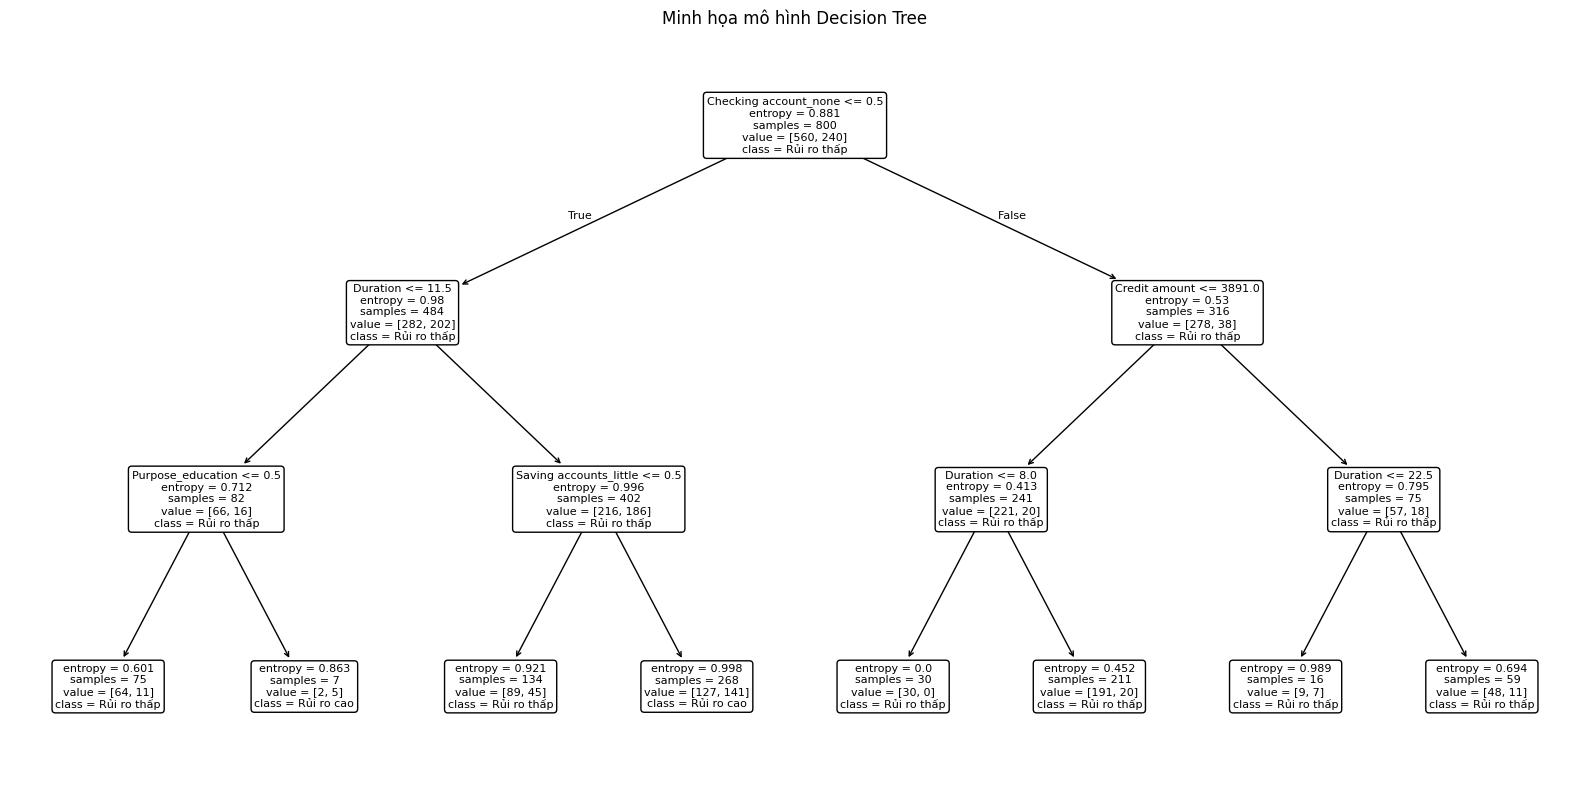

In [ ]:
# ============================================================
# 17. MÔ HÌNH MỞ RỘNG: DECISION TREE
# ============================================================
# Decision Tree được dùng để mở rộng và so sánh với Logistic Regression.
# Cây quyết định không bắt buộc chuẩn hóa dữ liệu, nhưng vẫn dùng dữ liệu đã mã hóa.

# Dùng dữ liệu chưa scale nhưng đã mã hóa one-hot.
dt_param_grid = {
    "max_depth": [2, 3, 4, 5, None],
    "min_samples_leaf": [1, 5, 10],
    "criterion": ["gini", "entropy"]
}

dt = DecisionTreeClassifier(random_state=42)

grid_dt = GridSearchCV(
    estimator=dt,
    param_grid=dt_param_grid,
    scoring="f1",
    cv=5,
    n_jobs=-1
)

grid_dt.fit(X_train_no_scaler, y_train)

best_dt = grid_dt.best_estimator_
y_pred_dt = best_dt.predict(X_test_no_scaler)
y_prob_dt = best_dt.predict_proba(X_test_no_scaler)[:, 1]

result_dt = evaluate_model(
    "Decision Tree mở rộng",
    y_test,
    y_pred_dt,
    y_prob_dt
)

print("\nTham số tốt nhất của Decision Tree:")
print(grid_dt.best_params_)


# Vẽ cây quyết định rút gọn để đưa vào báo cáo
plt.figure(figsize=(16, 8))
plot_tree(
    best_dt,
    feature_names=prep_no_scaler["feature_names"],
    class_names=["Rủi ro thấp", "Rủi ro cao"],
    filled=False,
    rounded=True,
    max_depth=3,
    fontsize=8
)
plt.title("Minh họa mô hình Decision Tree")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "fig_decision_tree.png"), dpi=300)
plt.show()



===== Logistic Regression tốt nhất =====
Accuracy : 0.675
Precision: 0.4762
Recall   : 0.8333
F1-score : 0.6061
ROC-AUC  : 0.7596

Ma trận nhầm lẫn:
[[85 55]
 [10 50]]

Classification report:
              precision    recall  f1-score   support

 Rủi ro thấp       0.89      0.61      0.72       140
  Rủi ro cao       0.48      0.83      0.61        60

    accuracy                           0.68       200
   macro avg       0.69      0.72      0.66       200
weighted avg       0.77      0.68      0.69       200


===== BẢNG SO SÁNH MÔ HÌNH =====
                                             Mo_hinh  Accuracy  Precision  \
0             Logistic tự xây dựng - Trước chuẩn hóa     0.700   0.500000   
1  Logistic tự xây dựng - Sau chuẩn hóa StandardS...     0.720   0.526316   
2                       Logistic Regression tốt nhất     0.675   0.476190   
3                              Decision Tree mở rộng     0.680   0.472222   

     Recall  F1_score   ROC_AUC  
0  0.116667  0.189189  0.6

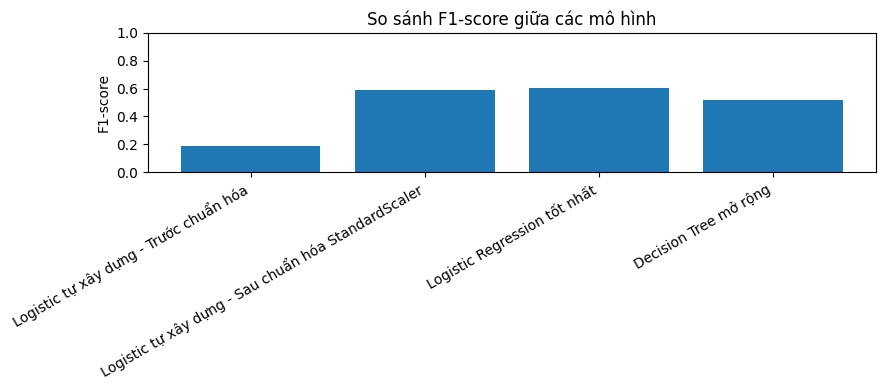

In [ ]:
# ============================================================
# 18. SO SÁNH LOGISTIC REGRESSION VÀ DECISION TREE
# ============================================================

result_best_logistic = evaluate_model(
    "Logistic Regression tốt nhất",
    y_test,
    best_pred,
    best_prob
)

model_comparison_df = pd.DataFrame([result_before, result_after, result_best_logistic, result_dt])
model_comparison_df.to_csv(os.path.join(OUTPUT_DIR, "bang_so_sanh_mo_hinh.csv"), index=False)

print("\n===== BẢNG SO SÁNH MÔ HÌNH =====")
print(model_comparison_df[["Mo_hinh", "Accuracy", "Precision", "Recall", "F1_score", "ROC_AUC"]])

plt.figure(figsize=(9, 4))
plt.bar(model_comparison_df["Mo_hinh"], model_comparison_df["F1_score"])
plt.ylabel("F1-score")
plt.ylim(0, 1)
plt.title("So sánh F1-score giữa các mô hình")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "fig_model_comparison_f1.png"), dpi=300)
plt.show()


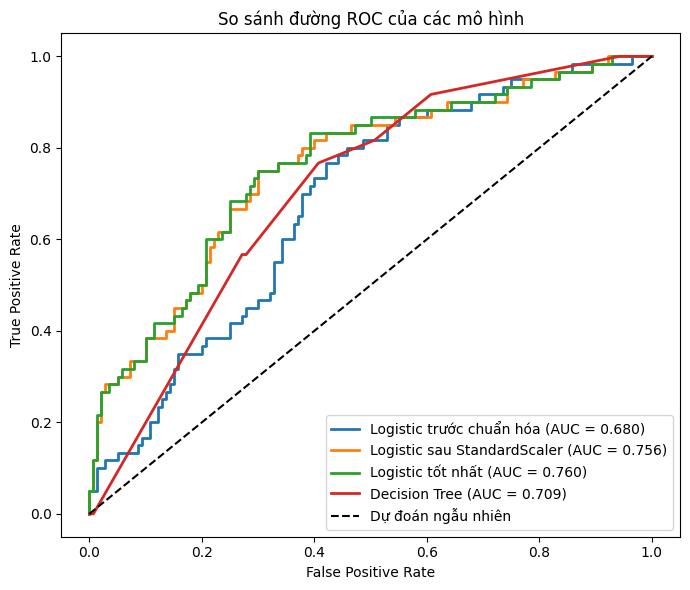

In [ ]:
# ============================================================
# 18.1 VẼ ĐƯỜNG ROC SO SÁNH 4 MÔ HÌNH
# ============================================================

plt.figure(figsize=(7,6))

# Logistic trước chuẩn hóa
fpr_before, tpr_before, _ = roc_curve(y_test, y_prob_before)
auc_before = roc_auc_score(y_test, y_prob_before)

plt.plot(
    fpr_before,
    tpr_before,
    linewidth=2,
    label=f"Logistic trước chuẩn hóa (AUC = {auc_before:.3f})"
)

# Logistic sau StandardScaler
fpr_after, tpr_after, _ = roc_curve(y_test, y_prob_after)
auc_after = roc_auc_score(y_test, y_prob_after)

plt.plot(
    fpr_after,
    tpr_after,
    linewidth=2,
    label=f"Logistic sau StandardScaler (AUC = {auc_after:.3f})"
)

# Logistic tốt nhất
fpr_best, tpr_best, _ = roc_curve(y_test, best_prob)
auc_best = roc_auc_score(y_test, best_prob)

plt.plot(
    fpr_best,
    tpr_best,
    linewidth=2,
    label=f"Logistic tốt nhất (AUC = {auc_best:.3f})"
)

# Decision Tree
fpr_dt, tpr_dt, _ = roc_curve(y_test, y_prob_dt)
auc_dt = roc_auc_score(y_test, y_prob_dt)

plt.plot(
    fpr_dt,
    tpr_dt,
    linewidth=2,
    label=f"Decision Tree (AUC = {auc_dt:.3f})"
)

# Đường chéo
plt.plot([0,1],[0,1],'k--',label="Dự đoán ngẫu nhiên")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("So sánh đường ROC của các mô hình")

plt.legend(loc="lower right")

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "fig_compare_roc_4_models.png"
    ),
    dpi=300
)

plt.show()


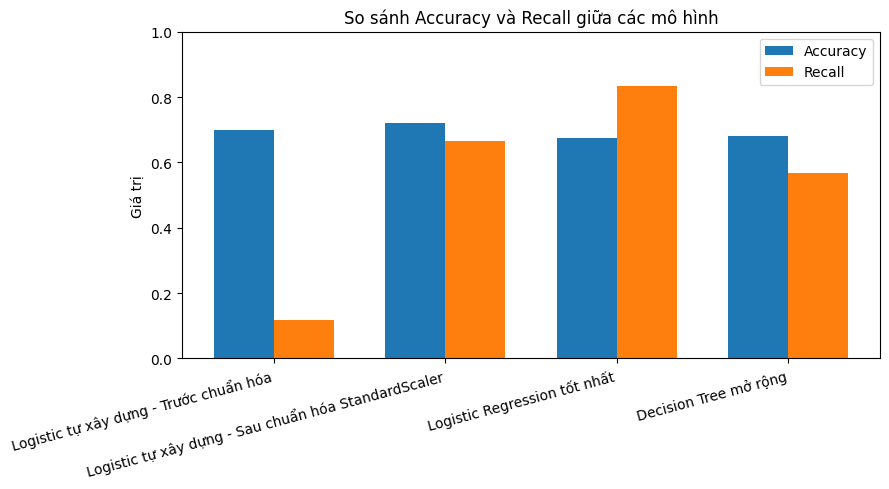

In [ ]:
# ============================================================
# 18.2 SO SÁNH ACCURACY VÀ RECALL GIỮA 4 MÔ HÌNH
# ============================================================

plt.figure(figsize=(9,5))

labels = model_comparison_df["Mo_hinh"]

accuracy = model_comparison_df["Accuracy"]
recall = model_comparison_df["Recall"]

x = np.arange(len(labels))
width = 0.35

plt.bar(
    x-width/2,
    accuracy,
    width,
    label="Accuracy"
)

plt.bar(
    x+width/2,
    recall,
    width,
    label="Recall"
)

plt.xticks(
    x,
    labels,
    rotation=15,
    ha="right"
)

plt.ylim(0,1)

plt.ylabel("Giá trị")

plt.title("So sánh Accuracy và Recall giữa các mô hình")

plt.legend()

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "fig_compare_accuracy_recall.png"
    ),
    dpi=300
)

plt.show()



18.3. PHÂN TÍCH ĐẶC TRƯNG ẢNH HƯỞNG ĐẾN KẾT QUẢ PHÂN NHÃN

===== TOP 15 ĐẶC TRƯNG ẢNH HƯỞNG MẠNH NHẤT =====
                    Dac_trung  He_so_Logistic  Muc_anh_huong_tuyet_doi  \
16      Checking account_none       -0.532742                 0.532742   
3                    Duration        0.488024                 0.488024   
14    Checking account_little        0.390880                 0.390880   
13       Saving accounts_rich       -0.240436                 0.240436   
11       Saving accounts_none       -0.226251                 0.226251   
21          Purpose_education        0.225753                 0.225753   
9      Saving accounts_little        0.199866                 0.199866   
10   Saving accounts_moderate        0.169905                 0.169905   
15  Checking account_moderate        0.167772                 0.167772   
23           Purpose_radio/TV       -0.145648                 0.145648   
25    Purpose_vacation/others       -0.123741                 0.123741   
24 

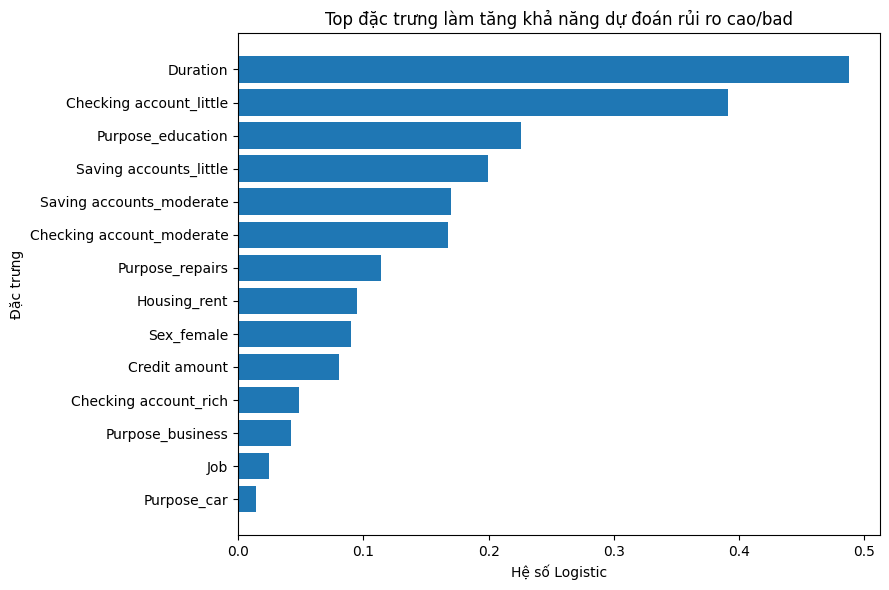


===== ĐÃ LƯU CÁC FILE PHÂN TÍCH ẢNH HƯỞNG ĐẶC TRƯNG =====
- bang_dac_trung_anh_huong_logistic.csv
- bang_du_lieu_test_kem_du_doan.csv
- bang_du_lieu_du_doan_sai.csv
- bang_giai_thich_cac_dong_du_doan_sai.csv
- bang_thong_ke_bien_so_theo_risk.csv
- bang_chenh_lech_bien_so_good_bad.csv
- bang_ty_le_bad_theo_bien_phan_loai.csv
- fig_top_dac_trung_tang_rui_ro_cao.png
- fig_top_dac_trung_tang_rui_ro_thap.png
- fig_top_dac_trung_anh_huong_manh_nhat.png
- fig_chenh_lech_bien_so_good_bad.png
- fig_ty_le_bad_theo_bien_phan_loai.png


In [ ]:
# ============================================================
# 18.3 PHÂN TÍCH DỮ LIỆU / ĐẶC TRƯNG ẢNH HƯỞNG ĐẾN KẾT QUẢ PHÂN NHÃN
# ============================================================
# Phần này giữ nguyên mô hình cũ, chỉ bổ sung thêm phân tích:
#   1. Đặc trưng nào làm tăng khả năng dự đoán "rủi ro cao/bad"
#   2. Đặc trưng nào làm tăng khả năng dự đoán "rủi ro thấp/good"
#   3. Những dòng dữ liệu nào bị dự đoán đúng/sai
#   4. Với các dòng bị dự đoán sai, đặc trưng nào tác động mạnh đến kết quả dự đoán
#
# Lưu ý:
#   - Logistic Regression là mô hình tuyến tính.
#   - Hệ số dương lớn  => làm tăng xác suất thuộc lớp 1: rủi ro cao/bad.
#   - Hệ số âm lớn    => làm giảm xác suất thuộc lớp 1, tức nghiêng về good.
#   - Giá trị tuyệt đối càng lớn thì đặc trưng càng ảnh hưởng mạnh.

print("\n" + "="*70)
print("18.3. PHÂN TÍCH ĐẶC TRƯNG ẢNH HƯỞNG ĐẾN KẾT QUẢ PHÂN NHÃN")
print("="*70)

# ------------------------------------------------------------
# 18.3.1. BẢNG HỆ SỐ LOGISTIC - MỨC ẢNH HƯỞNG CỦA TỪNG ĐẶC TRƯNG
# ------------------------------------------------------------

feature_names = prep_scaler["feature_names"]
coef_values = best_model.weights.ravel()

feature_effect_df = pd.DataFrame({
    "Dac_trung": feature_names,
    "He_so_Logistic": coef_values,
    "Muc_anh_huong_tuyet_doi": np.abs(coef_values)
})

feature_effect_df["Huong_anh_huong"] = np.where(
    feature_effect_df["He_so_Logistic"] > 0,
    "Tang xac suat rui ro cao/bad",
    "Tang xac suat rui ro thap/good"
)

feature_effect_df = feature_effect_df.sort_values(
    by="Muc_anh_huong_tuyet_doi",
    ascending=False
)

feature_effect_df.to_csv(
    os.path.join(OUTPUT_DIR, "bang_dac_trung_anh_huong_logistic.csv"),
    index=False,
    encoding="utf-8-sig"
)

print("\n===== TOP 15 ĐẶC TRƯNG ẢNH HƯỞNG MẠNH NHẤT =====")
print(feature_effect_df.head(15)[[
    "Dac_trung",
    "He_so_Logistic",
    "Muc_anh_huong_tuyet_doi",
    "Huong_anh_huong"
]])

# Top đặc trưng làm tăng rủi ro cao
top_bad_features = (
    feature_effect_df[feature_effect_df["He_so_Logistic"] > 0]
    .sort_values("He_so_Logistic", ascending=False)
    .head(15)
)

top_good_features = (
    feature_effect_df[feature_effect_df["He_so_Logistic"] < 0]
    .sort_values("He_so_Logistic", ascending=True)
    .head(15)
)

top_abs_features = feature_effect_df.head(20).copy()


print("\n===== TOP ĐẶC TRƯNG LÀM TĂNG KHẢ NĂNG RỦI RO CAO/BAD =====")
print(top_bad_features[["Dac_trung", "He_so_Logistic"]])

print("\n===== TOP ĐẶC TRƯNG LÀM TĂNG KHẢ NĂNG RỦI RO THẤP/GOOD =====")
print(top_good_features[["Dac_trung", "He_so_Logistic"]])


# ------------------------------------------------------------
# 18.3.2. BIỂU ĐỒ TOP ĐẶC TRƯNG LÀM TĂNG RỦI RO CAO
# ------------------------------------------------------------

plt.figure(figsize=(9, 6))
plt.barh(top_bad_features["Dac_trung"][::-1], top_bad_features["He_so_Logistic"][::-1])
plt.xlabel("Hệ số Logistic")
plt.ylabel("Đặc trưng")
plt.title("Top đặc trưng làm tăng khả năng dự đoán rủi ro cao/bad")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "fig_top_dac_trung_tang_rui_ro_cao.png"), dpi=300)
plt.show()
print("\n===== ĐÃ LƯU CÁC FILE PHÂN TÍCH ẢNH HƯỞNG ĐẶC TRƯNG =====")
print("- bang_dac_trung_anh_huong_logistic.csv")
print("- bang_du_lieu_test_kem_du_doan.csv")
print("- bang_du_lieu_du_doan_sai.csv")
print("- bang_giai_thich_cac_dong_du_doan_sai.csv")
print("- bang_thong_ke_bien_so_theo_risk.csv")
print("- bang_chenh_lech_bien_so_good_bad.csv")
print("- bang_ty_le_bad_theo_bien_phan_loai.csv")
print("- fig_top_dac_trung_tang_rui_ro_cao.png")
print("- fig_top_dac_trung_tang_rui_ro_thap.png")
print("- fig_top_dac_trung_anh_huong_manh_nhat.png")
print("- fig_chenh_lech_bien_so_good_bad.png")
print("- fig_ty_le_bad_theo_bien_phan_loai.png")


In [ ]:
# ============================================================
# 19. MINH HỌA DỰ ĐOÁN TRÊN DỮ LIỆU KHÁCH HÀNG MỚI
# ============================================================
# Ta tạo một khách hàng mới theo đúng các cột của dữ liệu Kaggle.
# Nếu tên cột không có trong dataset thì chương trình tự bỏ qua.

new_customer = {}

# Gán giá trị mặc định theo median/mode của tập train
for col in X_train_raw.columns:
    if col in prep_scaler["numeric_cols"]:
        new_customer[col] = prep_scaler["numeric_medians"][col]
    else:
        new_customer[col] = prep_scaler["categorical_modes"][col]

# Ghi đè một số thông tin minh họa cho khách hàng mới
# Các cột này đúng với German Credit Risk trên Kaggle.
if "Age" in new_customer:
    new_customer["Age"] = 35
if "Sex" in new_customer:
    new_customer["Sex"] = "male"
if "Job" in new_customer:
    new_customer["Job"] = 2
if "Housing" in new_customer:
    new_customer["Housing"] = "own"
if "Saving accounts" in new_customer:
    new_customer["Saving accounts"] = "little"
if "Checking account" in new_customer:
    new_customer["Checking account"] = "little"
if "Credit amount" in new_customer:
    new_customer["Credit amount"] = 7000
if "Duration" in new_customer:
    new_customer["Duration"] = 36
if "Purpose" in new_customer:
    new_customer["Purpose"] = "car"

new_customer_df = pd.DataFrame([new_customer])
print("\n===== DỮ LIỆU KHÁCH HÀNG MỚI =====")
print(new_customer_df)

new_customer_processed = transform_preprocessor(new_customer_df, prep_scaler)
new_prob = best_model.predict_proba(new_customer_processed)[0]
new_pred = int(new_prob >= best_setting["threshold"])

print("\n===== KẾT QUẢ DỰ ĐOÁN KHÁCH HÀNG MỚI =====")
print("Xác suất rủi ro cao:", round(new_prob, 4))

if new_pred == 1:
    print("Kết luận: Khách hàng thuộc nhóm RỦI RO TÀI CHÍNH CAO.")
else:
    print("Kết luận: Khách hàng thuộc nhóm RỦI RO TÀI CHÍNH THẤP.")


In [ ]:
# ============================================================
# 20. LƯU TỔNG HỢP KẾT QUẢ
# ============================================================

summary = {
    "Dataset": os.path.basename(LOCAL_CSV),
    "So_dong": df.shape[0],
    "So_cot_ban_dau": df.shape[1],
    "So_dac_trung_sau_ma_hoa": X_train_scaler.shape[1],
    "Ty_le_train": X_train_raw.shape[0],
    "Ty_le_test": X_test_raw.shape[0],
    "Best_Logistic_Params": str(best_setting),
    "Best_Logistic_F1": result_best_logistic["F1_score"],
    "Best_Logistic_ROC_AUC": result_best_logistic["ROC_AUC"],
    "Decision_Tree_Params": str(grid_dt.best_params_),
    "Decision_Tree_F1": result_dt["F1_score"],
    "Decision_Tree_ROC_AUC": result_dt["ROC_AUC"]
}

summary_df = pd.DataFrame([summary])
summary_df.to_csv(os.path.join(OUTPUT_DIR, "tong_hop_ket_qua.csv"), index=False)

print("\nĐã lưu toàn bộ kết quả vào thư mục:", OUTPUT_DIR)
print("Các file quan trọng:")
print("- bang_so_sanh_truoc_sau_chuan_hoa.csv")
print("- bang_khao_nghiem_logistic.csv")
print("- bang_so_sanh_mo_hinh.csv")
print("- fig_before_after_scaling.png")
print("- fig_confusion_matrix.png")
print("- fig_roc_logistic.png")
print("- fig_model_comparison_f1.png")

print("- bang_dac_trung_anh_huong_logistic.csv")
print("- bang_du_lieu_test_kem_du_doan.csv")
print("- bang_du_lieu_du_doan_sai.csv")
print("- bang_giai_thich_cac_dong_du_doan_sai.csv")
print("- bang_thong_ke_bien_so_theo_risk.csv")
print("- bang_chenh_lech_bien_so_good_bad.csv")
print("- bang_ty_le_bad_theo_bien_phan_loai.csv")
print("- fig_top_dac_trung_tang_rui_ro_cao.png")
print("- fig_top_dac_trung_tang_rui_ro_thap.png")
print("- fig_top_dac_trung_anh_huong_manh_nhat.png")
print("- fig_chenh_lech_bien_so_good_bad.png")
print("- fig_ty_le_bad_theo_bien_phan_loai.png")
